#  TNS T1708005 CAPSTONE PROJECT 1

## Data Science Capstone Project: Manufacturing Equipment Output Prediction with Linear Regression





SHIVAM KAMLESH YADAV

PRATHAMESH VIJAY TIKLE

SAKSHI SATISH YADAV

KAPIL SHIVRAJ CHAWALE

SAMRUDDHI PRANIL KASOTE

In [16]:
import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()

Saving manufacturing_dataset_1000_samples.csv to manufacturing_dataset_1000_samples (1).csv


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('manufacturing_dataset_1000_samples.csv')
df.shape
print(df.isnull().sum())
df.head()

Timestamp                      0
Injection_Temperature          0
Injection_Pressure             0
Cycle_Time                     0
Cooling_Time                   0
Material_Viscosity            20
Ambient_Temperature           20
Machine_Age                    0
Operator_Experience           20
Maintenance_Hours              0
Shift                          0
Machine_Type                   0
Material_Grade                 0
Day_of_Week                    0
Temperature_Pressure_Ratio     0
Total_Cycle_Time               0
Efficiency_Score               0
Machine_Utilization            0
Parts_Per_Hour                 0
dtype: int64


,Timestamp,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Shift,Machine_Type,Material_Grade,Day_of_Week,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization,Parts_Per_Hour
0,2023-01-01 00:00:00,221.0,136.0,28.7,13.6,375.5,28.0,3.8,11.2,64,Evening,Type_B,Economy,Thursday,1.625,42.3,0.063,0.510,36.5
1,2023-01-01 01:00:00,213.3,128.9,34.5,14.0,215.8,22.6,6.8,6.3,58,Night,Type_A,Standard,Wednesday,1.655,48.5,0.037,0.389,29.9
2,2023-01-01 02:00:00,222.8,115.9,19.9,9.5,307.0,25.3,4.2,9.6,47,Day,Type_A,Standard,Monday,1.922,29.4,0.061,0.551,56.9
3,2023-01-01 03:00:00,233.3,105.3,39.2,13.1,137.8,26.0,9.2,8.6,49,Evening,Type_A,Premium,Saturday,2.215,52.3,0.054,0.293,31.0
4,2023-01-01 04:00:00,212.2,125.5,45.0,9.9,298.2,23.6,6.2,23.0,49,Night,Type_B,Premium,Monday,1.691,54.9,0.145,0.443,15.0


In [18]:
print(df.isnull().sum()[df.isnull().sum() > 0])

missing_cols = ['Material_Viscosity', 'Ambient_Temperature', 'Operator_Experience']
for col in missing_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

duplicate_count = df.duplicated().sum()
if duplicate_count > 0:
    df = df.drop_duplicates()
print(f"\nDuplicates removed: {duplicate_count}")


print("Missing values after cleaning:", df.isnull().sum().sum())

Material_Viscosity     20
Ambient_Temperature    20
Operator_Experience    20
dtype: int64

Duplicates removed: 0
Missing values after cleaning: 0


,count,mean,std,min,50%,max
Injection_Temperature,1000.0,215.315900,11.995507,180.000,215.3000,300.000
Injection_Pressure,1000.0,116.075000,14.667246,80.000,115.9500,150.000
Cycle_Time,1000.0,35.851700,8.353490,16.300,36.8500,60.000
Cooling_Time,1000.0,11.923200,2.304290,8.000,11.9000,19.900
Material_Viscosity,1000.0,251.452100,72.621536,104.600,242.7000,1000.000
Ambient_Temperature,1000.0,22.940400,2.745813,18.000,22.9000,28.000
Machine_Age,1000.0,7.855900,3.900798,1.000,7.9000,15.000
Operator_Experience,1000.0,30.621300,27.433292,1.000,22.1000,120.000
Maintenance_Hours,1000.0,50.580000,16.014558,26.000,50.0000,500.000
Temperature_Pressure_Ratio,1000.0,1.885852,0.274323,1.286,1.8495,2.843



Correlation with Parts_Per_Hour:
 Parts_Per_Hour                1.000000
Operator_Experience           0.297100
Efficiency_Score              0.286794
Injection_Temperature         0.184353
Machine_Utilization           0.174573
Injection_Pressure            0.160362
Ambient_Temperature           0.011729
Cooling_Time                  0.006215
Maintenance_Hours            -0.032955
Material_Viscosity           -0.080036
Temperature_Pressure_Ratio   -0.086113
Machine_Age                  -0.174518
Total_Cycle_Time             -0.792862
Cycle_Time                   -0.819446
Name: Parts_Per_Hour, dtype: float64


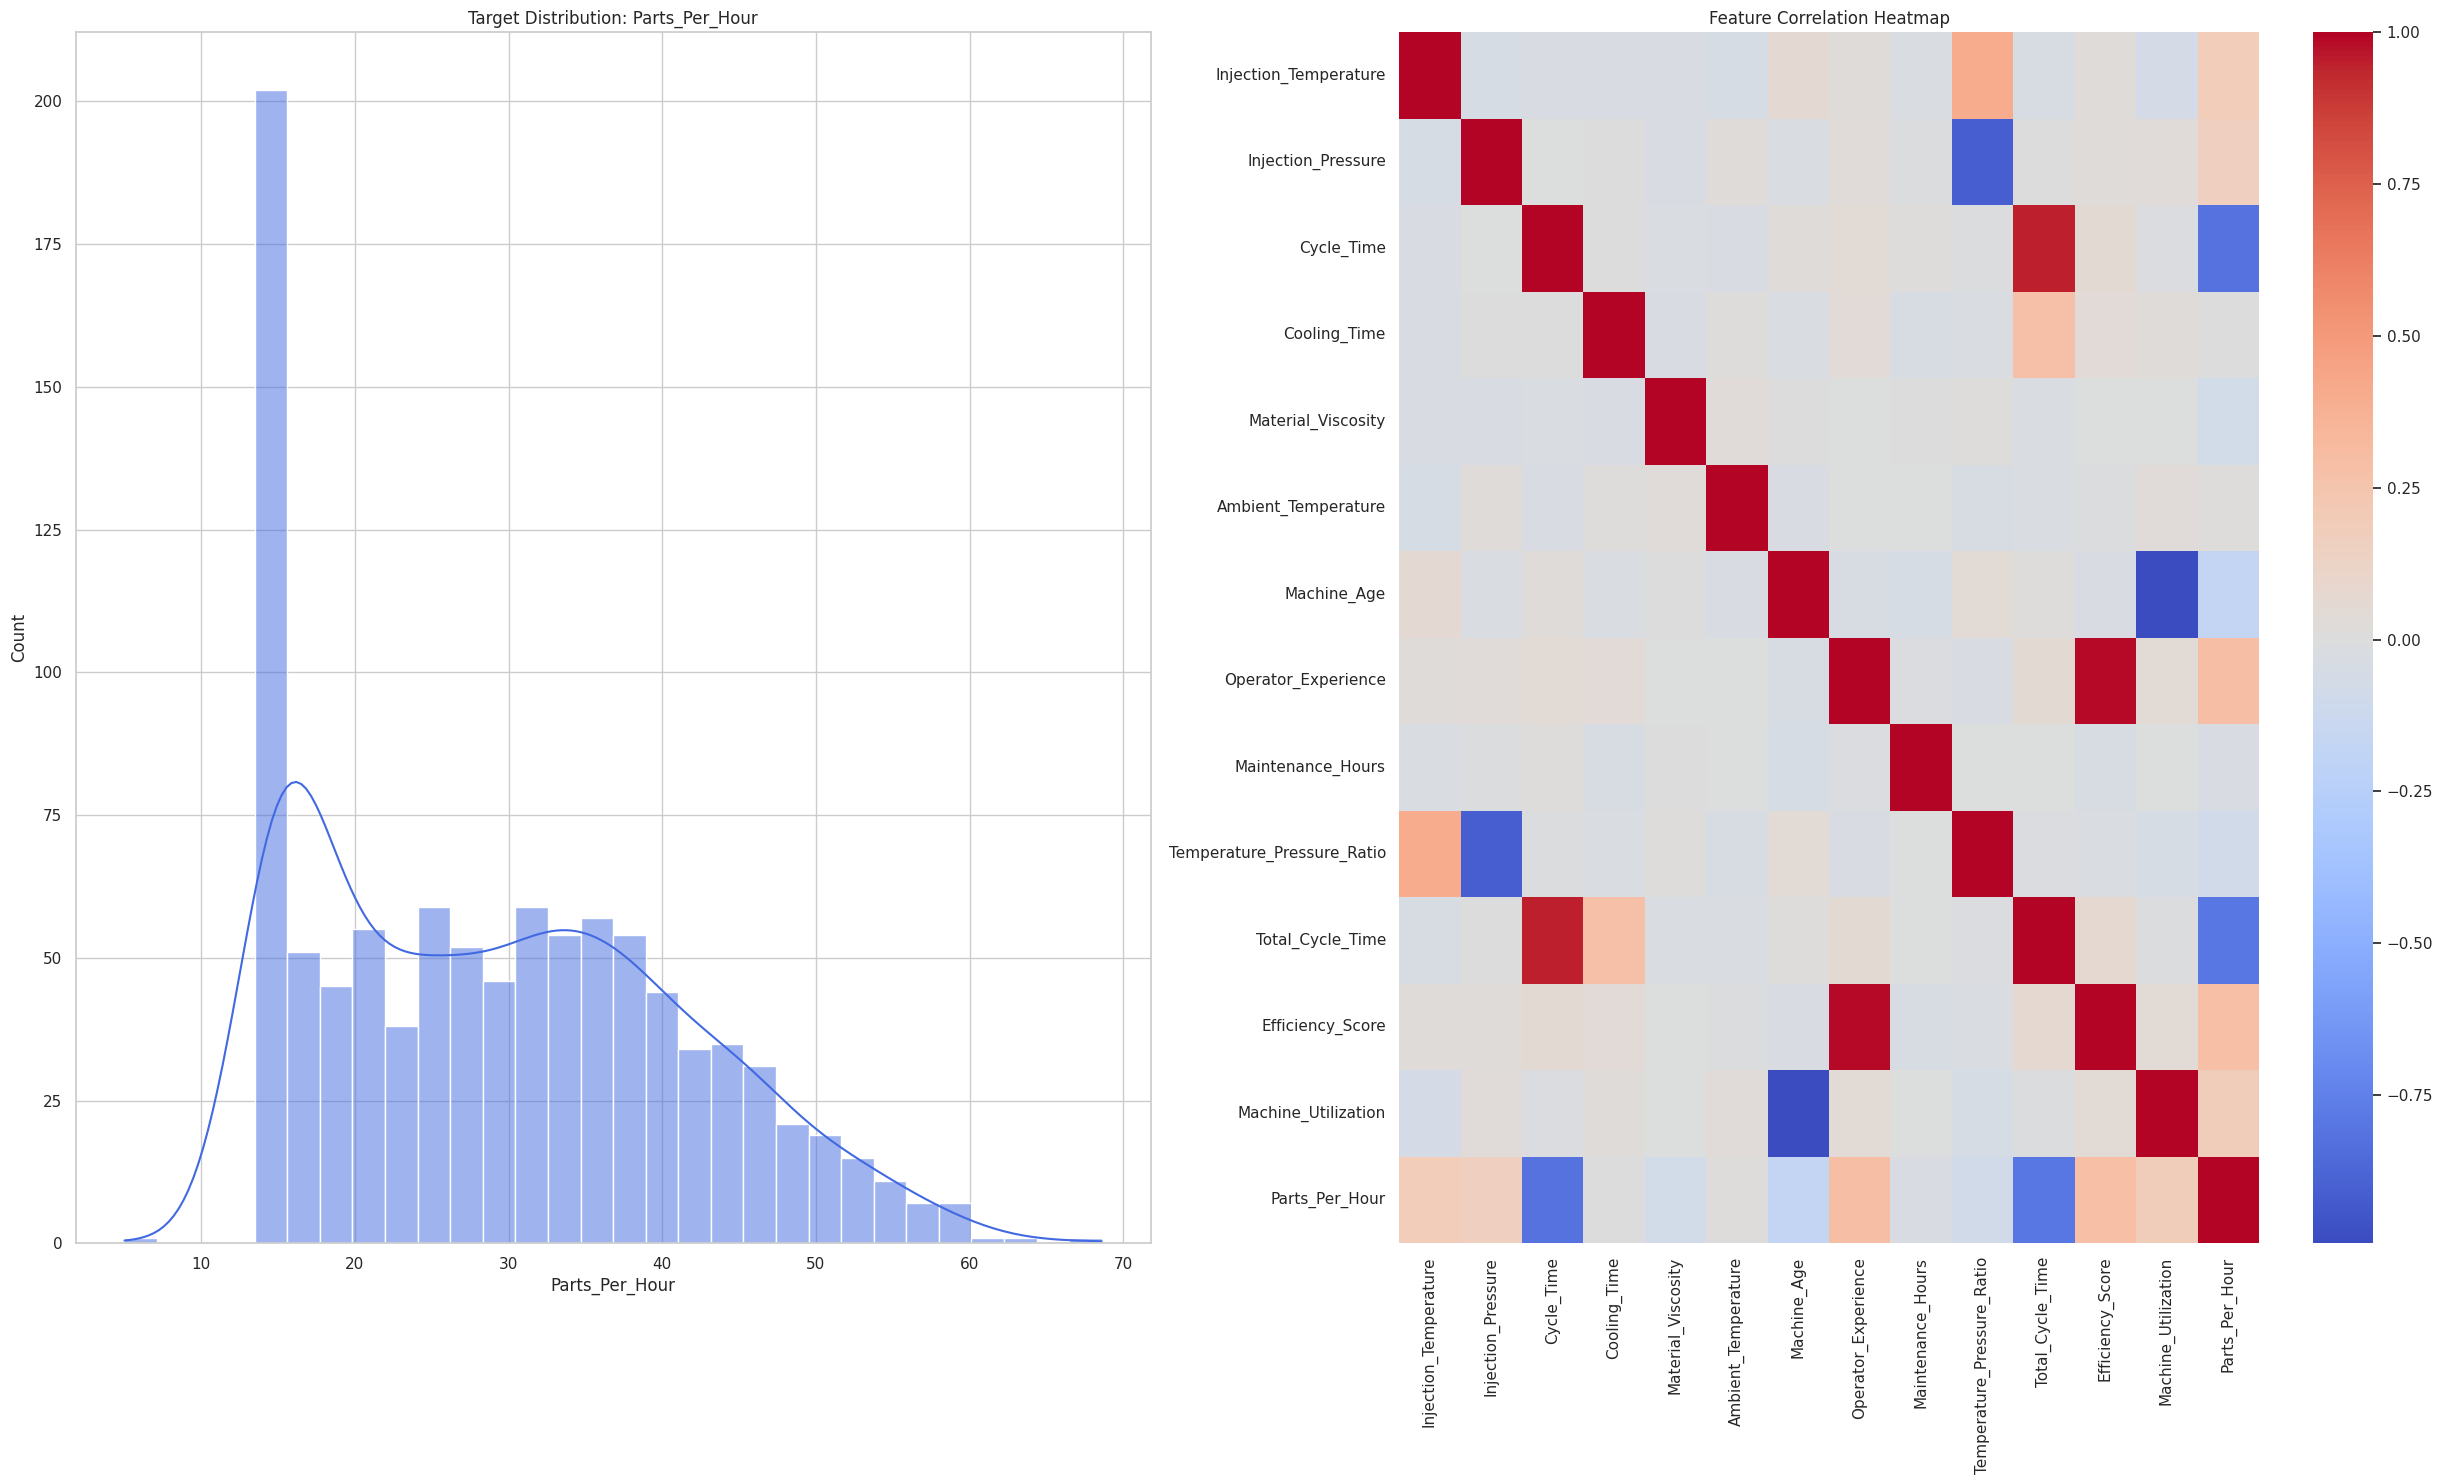

In [19]:
sns.set_theme(style="whitegrid")
display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])


num_cols = df.select_dtypes(include=[np.number]).columns
corr_target = df[num_cols].corr()['Parts_Per_Hour'].sort_values(ascending=False)
print("\nCorrelation with Parts_Per_Hour:\n", corr_target)


fig, axes = plt.subplots(1, 2, figsize=(25, 15))


sns.histplot(df['Parts_Per_Hour'], kde=True, ax=axes[0], color='royalblue', bins=30)
axes[0].set_title('Target Distribution: Parts_Per_Hour')


sns.heatmap(df[num_cols].corr(), cmap='coolwarm', ax=axes[1], annot=False)
axes[1].set_title('Feature Correlation Heatmap')

plt.tight_layout()
plt.show()

In [20]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Production_Hour'] = df['Timestamp'].dt.hour
df['Production_Month'] = df['Timestamp'].dt.month

df = df.drop(columns=['Timestamp'])

print("Timestamp processed into numeric time features. Current columns:")
print(df.columns.tolist())

Timestamp processed into numeric time features. Current columns:
['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Machine_Age', 'Operator_Experience', 'Maintenance_Hours', 'Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week', 'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score', 'Machine_Utilization', 'Parts_Per_Hour', 'Production_Hour', 'Production_Month']


In [21]:
df['Cooling_to_Cycle_Ratio'] = df['Cooling_Time'] / (df['Cycle_Time'] + 1e-5)

df['Maintenance_per_Age'] = df['Maintenance_Hours'] / (df['Machine_Age'] + 0.1)

print(df[['Cooling_to_Cycle_Ratio', 'Maintenance_per_Age', 'Parts_Per_Hour']].corr()['Parts_Per_Hour'])

Cooling_to_Cycle_Ratio    0.643668
Maintenance_per_Age       0.057737
Parts_Per_Hour            1.000000
Name: Parts_Per_Hour, dtype: float64


In [22]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Parts_Per_Hour'])
y = df['Parts_Per_Hour']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}")
print(f"X_test Shape:  {X_test.shape} | y_test Shape:  {y_test.shape}")

X_train Shape: (800, 21) | y_train Shape: (800,)
X_test Shape:  (200, 21) | y_test Shape:  (200,)


In [23]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(include=['object']).columns.tolist()

In [24]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [26]:
# Use our trained simplified model and the scaled test data
y_pred = model.predict(X_test_scaled)

# Create a table comparing our actual vs predicted parts per hour
predictions_df = pd.DataFrame({
    'Actual_Parts_Per_Hour': y_test.values,
    'Predicted_Parts_Per_Hour': np.round(y_pred, 2),
    'Absolute_Error': np.round(np.abs(y_test.values - y_pred), 2)
})

print("Sample Predictions:")
display(predictions_df.head(10))

Sample Predictions:


,Actual_Parts_Per_Hour,Predicted_Parts_Per_Hour,Absolute_Error
0,18.6,20.39,1.79
1,42.8,44.85,2.05
2,34.2,35.30,1.10
3,40.0,39.67,0.33
4,15.0,18.44,3.44
5,15.0,20.11,5.11
6,33.6,33.81,0.21
7,15.0,13.29,1.71
8,25.0,28.35,3.35
9,24.2,32.77,8.57


In [27]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


In [28]:
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):  {rmse:.4f}")
print(f"Mean Absolute Error (MAE):       {mae:.4f}")
print(f"R-squared Score (R²):            {r2:.4f}")

threshold = 20.0
y_test_bin = (y_test < threshold).astype(int)
y_pred_bin = (y_pred < threshold).astype(int)


print(f"Accuracy:  {accuracy_score(y_test_bin, y_pred_bin):.4f}")
print(f"Precision: {precision_score(y_test_bin, y_pred_bin):.4f}")
print(f"Recall:    {recall_score(y_test_bin, y_pred_bin):.4f}")
print(f"F1-Score:  {f1_score(y_test_bin, y_pred_bin):.4f}")

Mean Squared Error (MSE):       12.4106
Root Mean Squared Error (RMSE):  3.5229
Mean Absolute Error (MAE):       2.6793
R-squared Score (R²):            0.9049
Accuracy:  0.9100
Precision: 0.9636
Recall:    0.7681
F1-Score:  0.8548


In [30]:
new_data = pd.DataFrame({
    'Injection_Temperature': [221.5],
    'Injection_Pressure': [123.7],
    'Cycle_Time': [40.9],
    'Cooling_Time': [11.0],
    'Material_Viscosity': [144.9],
    'Ambient_Temperature': [24.0],
    'Machine_Age': [13.0],
    'Operator_Experience': [5.5],
    'Maintenance_Hours': [42],
    'Shift': ['Evening'],
    'Machine_Type': ['Type_A'],
    'Material_Grade': ['Economy'],
    'Day_of_Week': ['Friday'],
    'Temperature_Pressure_Ratio': [1.79],
    'Total_Cycle_Time': [51.8],
    'Efficiency_Score': [0.036],
    'Machine_Utilization': [0.107],
    'Production_Hour': [17],
    'Production_Month': [1],
    'Cooling_to_Cycle_Ratio': [11.0 / 40.9],
    'Maintenance_per_Age': [42 / 13.1]
})


In [31]:

new_data_encoded = pd.get_dummies(new_data, drop_first=True)

_, new_data_encoded = X_train_encoded.align(new_data_encoded, join='left', axis=1, fill_value=0)

new_data_scaled = scaler.transform(new_data_encoded)

prediction = model.predict(new_data_scaled)

print(f"Predicted Parts Per Hour: {prediction[0]:.2f}")
if prediction[0] < 20.0:
    print("Warning: Machine is predicted to be Underperforming!")
else:
    print("Status: Machine operating within normal performance range.")

Predicted Parts Per Hour: 22.13
Status: Machine operating within normal performance range.
